# Telecom Customer Churn Prediction - Exploratory Data Analysis (EDA)

This notebook performs initial exploratory data analysis on the Telco Customer Churn dataset.

### Objectives:
- Load the dataset without modifying raw data
- Inspect dataset shape, structure, column data types, and duplicates
- Convert `TotalCharges` to numeric and identify missing/whitespace values
- Analyze target variable (`Churn`) distribution
- Explore demographic, contract, tenure, and billing relationships with churn
- Save generated figures to the `outputs/` folder


In [1]:
# 1. Import necessary libraries and configure paths & visualization styles
import os
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Set visualization styles
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["font.size"] = 11

# Define paths robustly whether executed from project root or notebooks/
if Path("dataset/Telco-Customer-Churn.csv").exists():
    DATA_PATH = Path("dataset/Telco-Customer-Churn.csv")
    OUTPUTS_DIR = Path("outputs")
else:
    DATA_PATH = Path("../dataset/Telco-Customer-Churn.csv")
    OUTPUTS_DIR = Path("../outputs")

OUTPUTS_DIR.mkdir(parents=True, exist_ok=True)

print(f"Data Path: {DATA_PATH.resolve()}")
print(f"Outputs Directory: {OUTPUTS_DIR.resolve()}")


Data Path: C:\Users\adith\OneDrive\Documents\Desktop\Telecom\dataset\Telco-Customer-Churn.csv
Outputs Directory: C:\Users\adith\OneDrive\Documents\Desktop\Telecom\outputs


## 2. Load Dataset

In [2]:
# Load CSV dataset using Pandas
df = pd.read_csv(DATA_PATH)
print("Dataset successfully loaded into DataFrame.")


Dataset successfully loaded into DataFrame.


## 3. Dataset Overview: Shape, First 5 Rows, Column Names, and Data Types

In [3]:
# Display dataset shape
print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")


Dataset Shape: 7043 rows, 21 columns


In [4]:
# Display first 5 rows
df.head()


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
# Display Column Names
print("Column Names:")
for i, col in enumerate(df.columns, 1):
    print(f"  {i:2d}. {col}")


Column Names:
   1. customerID
   2. gender
   3. SeniorCitizen
   4. Partner
   5. Dependents
   6. tenure
   7. PhoneService
   8. MultipleLines
   9. InternetService
  10. OnlineSecurity
  11. OnlineBackup
  12. DeviceProtection
  13. TechSupport
  14. StreamingTV
  15. StreamingMovies
  16. Contract
  17. PaperlessBilling
  18. PaymentMethod
  19. MonthlyCharges
  20. TotalCharges
  21. Churn


In [6]:
# Display Data Types and Summary Info
print("Data Types and Non-Null Count Summary:")
df.info()


Data Types and Non-Null Count Summary:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilli

## 4. Missing Values & Duplicate Records Analysis

In [7]:
# Check for missing values in raw dataset
print("Missing values per column in raw data:")
raw_missing = df.isnull().sum()
print(raw_missing)
print(f"Total raw missing values detected: {raw_missing.sum()}")


Missing values per column in raw data:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64
Total raw missing values detected: 0


In [8]:
# Check for duplicate records
duplicate_count = df.duplicated().sum()
print(f"Number of duplicate records: {duplicate_count}")


Number of duplicate records: 0


## 5. TotalCharges Numeric Conversion & Missing Values Identification
In the raw data, `TotalCharges` is stored as `object` (string). Blank spaces (`' '`) exist for new customers with 0 tenure.
Here we convert `TotalCharges` to numeric without deleting or altering records in the original CSV file.


In [9]:
# Identify whitespace / blank records in TotalCharges
whitespace_count = (df['TotalCharges'].astype(str).str.strip() == '').sum()
print(f"Number of records with whitespace/empty string in TotalCharges: {whitespace_count}")

# Inspect sample records with whitespace TotalCharges
blank_records = df[df['TotalCharges'].astype(str).str.strip() == '']
print("\nSample records with blank TotalCharges (all have tenure == 0):")
blank_records[['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Contract', 'Churn']].head(11)


Number of records with whitespace/empty string in TotalCharges: 11

Sample records with blank TotalCharges (all have tenure == 0):


,customerID,tenure,MonthlyCharges,TotalCharges,Contract,Churn
488,4472-LVYGI,0,52.55,,Two year,No
753,3115-CZMZD,0,20.25,,Two year,No
936,5709-LVOEQ,0,80.85,,Two year,No
1082,4367-NUYAO,0,25.75,,Two year,No
1340,1371-DWPAZ,0,56.05,,Two year,No
3331,7644-OMVMY,0,19.85,,Two year,No
3826,3213-VVOLG,0,25.35,,Two year,No
4380,2520-SGTTA,0,20.00,,Two year,No
5218,2923-ARZLG,0,19.70,,One year,No
6670,4075-WKNIU,0,73.35,,Two year,No


In [10]:
# Convert TotalCharges to numeric, coercing blank spaces to NaN
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# Verify dtype and count NaNs
missing_total_charges = df['TotalCharges'].isna().sum()
print(f"TotalCharges new data type: {df['TotalCharges'].dtype}")
print(f"Missing values (NaN) in TotalCharges after numeric conversion: {missing_total_charges}")
print(f"Percentage of missing TotalCharges: {(missing_total_charges / len(df)) * 100:.3f}%")


TotalCharges new data type: float64
Missing values (NaN) in TotalCharges after numeric conversion: 11
Percentage of missing TotalCharges: 0.156%


## 6. Churn Distribution

In [11]:
# Display Churn distribution table
churn_counts = df['Churn'].value_counts()
churn_percentages = df['Churn'].value_counts(normalize=True) * 100

churn_dist_df = pd.DataFrame({
    'Count': churn_counts,
    'Percentage (%)': churn_percentages.round(2)
})

print("Churn Distribution:")
churn_dist_df


Churn Distribution:


,Count,Percentage (%)
Churn,,
No,5174,73.46
Yes,1869,26.54


## 7. Exploratory Visualizations
We generate and save visualizations for:
1. Churn distribution
2. Gender vs Churn
3. Contract type vs Churn
4. Tenure vs Churn
5. Monthly charges vs Churn
All figures are saved to `outputs/`.


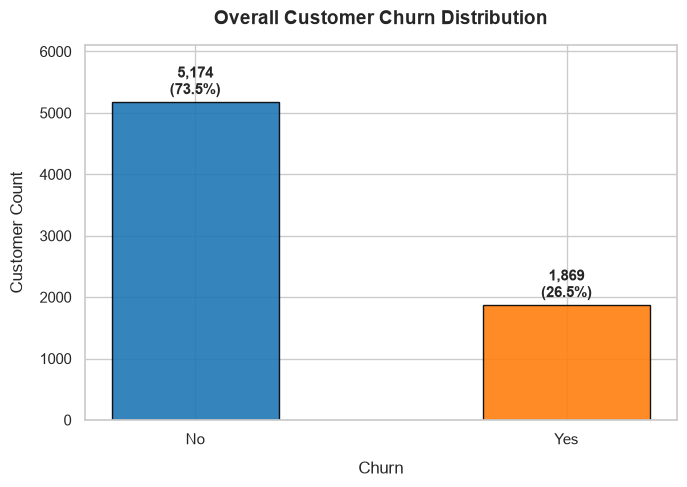

Saved: C:\Users\adith\OneDrive\Documents\Desktop\Telecom\outputs\churn_distribution.png


In [12]:
# Visualization 1: Churn distribution
fig, ax = plt.subplots(figsize=(7, 5))
colors = ['#1f77b4', '#ff7f0e']
bars = ax.bar(churn_counts.index, churn_counts.values, color=colors, width=0.45, edgecolor='black', alpha=0.9)

for bar in bars:
    height = bar.get_height()
    pct = (height / len(df)) * 100
    ax.text(bar.get_x() + bar.get_width() / 2, height + 60, f"{height:,}\n({pct:.1f}%)",
            ha='center', va='bottom', fontsize=11, fontweight='bold')

ax.set_title("Overall Customer Churn Distribution", fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel("Churn", fontsize=12, labelpad=10)
ax.set_ylabel("Customer Count", fontsize=12, labelpad=10)
ax.set_ylim(0, max(churn_counts.values) * 1.18)

save_path_1 = OUTPUTS_DIR / "churn_distribution.png"
plt.tight_layout()
fig.savefig(save_path_1, dpi=300)
plt.show()
print(f"Saved: {save_path_1.resolve()}")


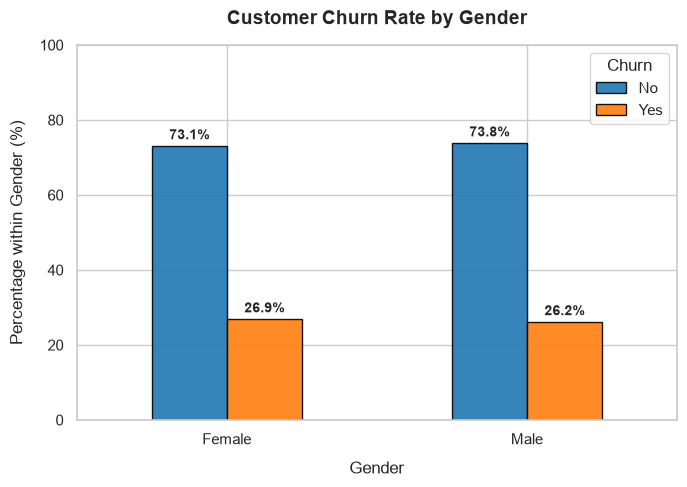

Saved: C:\Users\adith\OneDrive\Documents\Desktop\Telecom\outputs\gender_vs_churn.png


In [13]:
# Visualization 2: Gender vs Churn
fig, ax = plt.subplots(figsize=(7, 5))

gender_churn = pd.crosstab(df['gender'], df['Churn'], normalize='index') * 100
gender_churn.plot(kind='bar', ax=ax, color=['#1f77b4', '#ff7f0e'], edgecolor='black', alpha=0.9, width=0.5)

for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f"{height:.1f}%",
                    (p.get_x() + p.get_width() / 2., height + 1),
                    ha='center', va='bottom', fontsize=10, fontweight='bold')

ax.set_title("Customer Churn Rate by Gender", fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel("Gender", fontsize=12, labelpad=10)
ax.set_ylabel("Percentage within Gender (%)", fontsize=12, labelpad=10)
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
ax.set_ylim(0, 100)
ax.legend(title="Churn", loc="upper right")

save_path_2 = OUTPUTS_DIR / "gender_vs_churn.png"
plt.tight_layout()
fig.savefig(save_path_2, dpi=300)
plt.show()
print(f"Saved: {save_path_2.resolve()}")


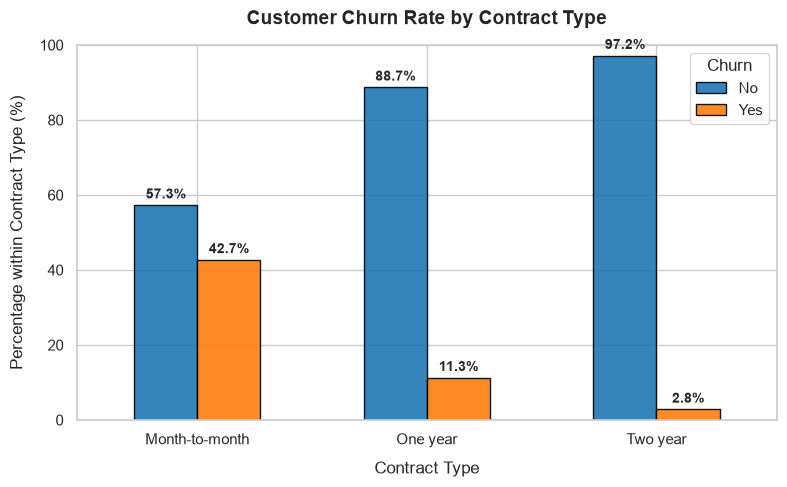

Saved: C:\Users\adith\OneDrive\Documents\Desktop\Telecom\outputs\contract_type_vs_churn.png


In [14]:
# Visualization 3: Contract Type vs Churn
fig, ax = plt.subplots(figsize=(8, 5))

contract_order = ['Month-to-month', 'One year', 'Two year']
contract_churn = pd.crosstab(df['Contract'], df['Churn'], normalize='index').reindex(contract_order) * 100
contract_churn.plot(kind='bar', ax=ax, color=['#1f77b4', '#ff7f0e'], edgecolor='black', alpha=0.9, width=0.55)

for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f"{height:.1f}%",
                    (p.get_x() + p.get_width() / 2., height + 1),
                    ha='center', va='bottom', fontsize=10, fontweight='bold')

ax.set_title("Customer Churn Rate by Contract Type", fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel("Contract Type", fontsize=12, labelpad=10)
ax.set_ylabel("Percentage within Contract Type (%)", fontsize=12, labelpad=10)
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
ax.set_ylim(0, 100)
ax.legend(title="Churn", loc="upper right")

save_path_3 = OUTPUTS_DIR / "contract_type_vs_churn.png"
plt.tight_layout()
fig.savefig(save_path_3, dpi=300)
plt.show()
print(f"Saved: {save_path_3.resolve()}")


C:\Users\adith\AppData\Local\Temp\ipykernel_14204\443199523.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Churn', y='tenure',


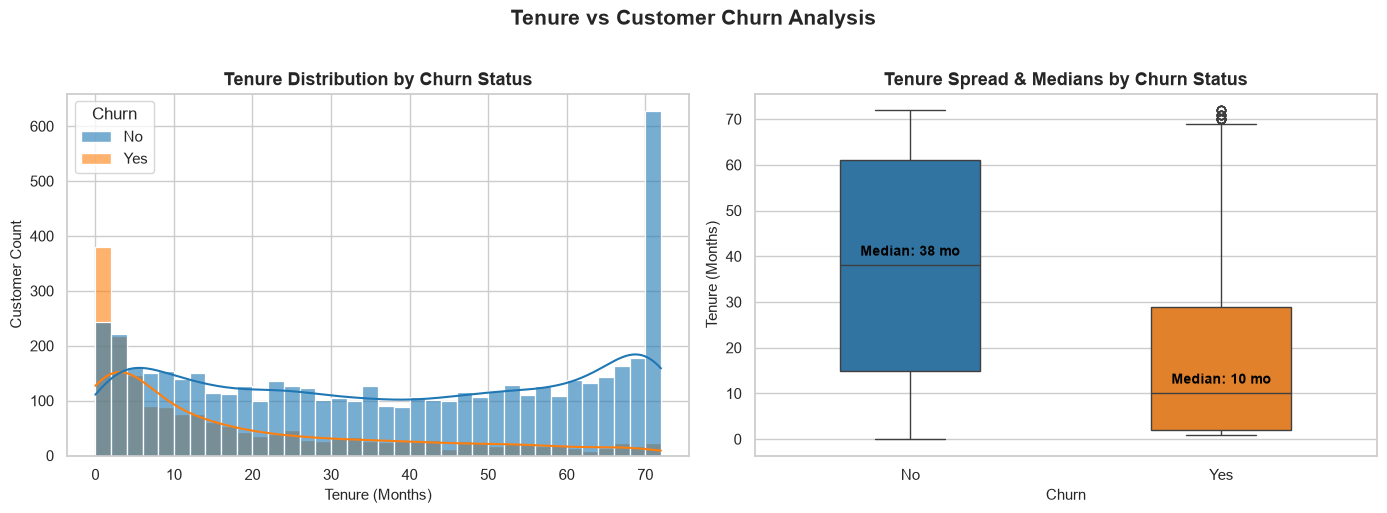

Saved: C:\Users\adith\OneDrive\Documents\Desktop\Telecom\outputs\tenure_vs_churn.png


In [15]:
# Visualization 4: Tenure vs Churn
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Distribution histogram & KDE
sns.histplot(data=df, x='tenure', hue='Churn', kde=True, multiple='layer',
             palette={'No': '#1f77b4', 'Yes': '#ff7f0e'}, ax=ax1, bins=36, alpha=0.6)
ax1.set_title("Tenure Distribution by Churn Status", fontsize=13, fontweight='bold')
ax1.set_xlabel("Tenure (Months)", fontsize=11)
ax1.set_ylabel("Customer Count", fontsize=11)

# Boxplot
sns.boxplot(data=df, x='Churn', y='tenure',
            palette={'No': '#1f77b4', 'Yes': '#ff7f0e'}, ax=ax2, width=0.45)
ax2.set_title("Tenure Spread & Medians by Churn Status", fontsize=13, fontweight='bold')
ax2.set_xlabel("Churn", fontsize=11)
ax2.set_ylabel("Tenure (Months)", fontsize=11)

medians_tenure = df.groupby('Churn')['tenure'].median()
for i, median in enumerate(medians_tenure):
    ax2.text(i, median + 1.5, f"Median: {median:.0f} mo",
             ha='center', va='bottom', color='black', fontweight='bold', fontsize=10)

plt.suptitle("Tenure vs Customer Churn Analysis", fontsize=15, fontweight='bold', y=1.02)

save_path_4 = OUTPUTS_DIR / "tenure_vs_churn.png"
plt.tight_layout()
fig.savefig(save_path_4, dpi=300, bbox_inches='tight')
plt.show()
print(f"Saved: {save_path_4.resolve()}")


C:\Users\adith\AppData\Local\Temp\ipykernel_14204\2658964832.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Churn', y='MonthlyCharges',


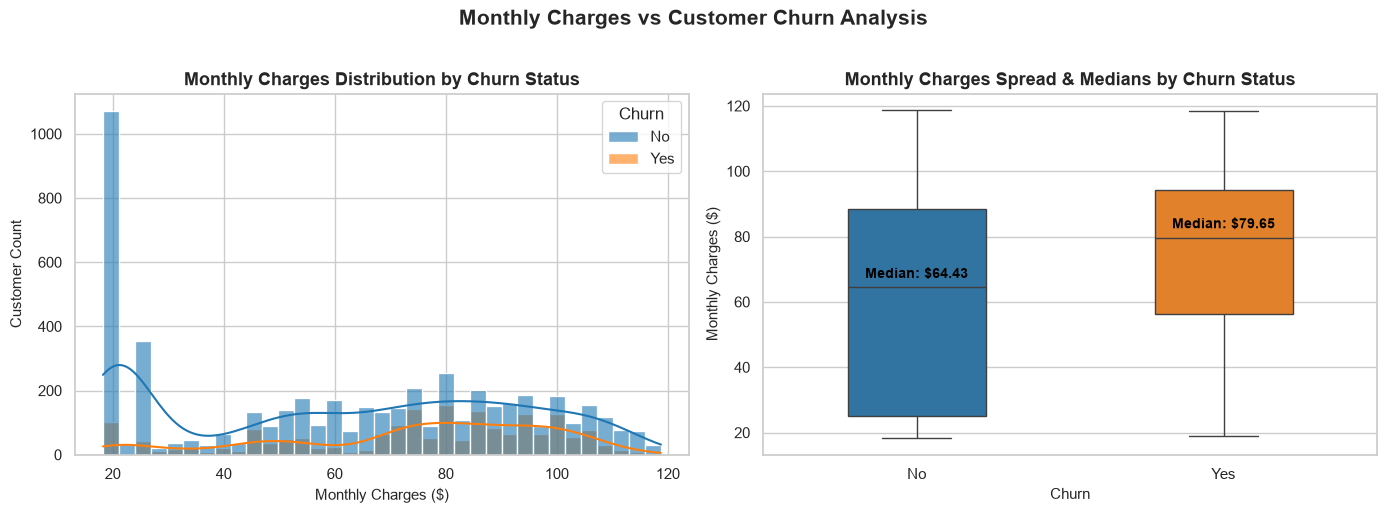

Saved: C:\Users\adith\OneDrive\Documents\Desktop\Telecom\outputs\monthly_charges_vs_churn.png


In [16]:
# Visualization 5: Monthly Charges vs Churn
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Distribution histogram & KDE
sns.histplot(data=df, x='MonthlyCharges', hue='Churn', kde=True, multiple='layer',
             palette={'No': '#1f77b4', 'Yes': '#ff7f0e'}, ax=ax1, bins=35, alpha=0.6)
ax1.set_title("Monthly Charges Distribution by Churn Status", fontsize=13, fontweight='bold')
ax1.set_xlabel("Monthly Charges ($)", fontsize=11)
ax1.set_ylabel("Customer Count", fontsize=11)

# Boxplot
sns.boxplot(data=df, x='Churn', y='MonthlyCharges',
            palette={'No': '#1f77b4', 'Yes': '#ff7f0e'}, ax=ax2, width=0.45)
ax2.set_title("Monthly Charges Spread & Medians by Churn Status", fontsize=13, fontweight='bold')
ax2.set_xlabel("Churn", fontsize=11)
ax2.set_ylabel("Monthly Charges ($)", fontsize=11)

medians_mc = df.groupby('Churn')['MonthlyCharges'].median()
for i, median in enumerate(medians_mc):
    ax2.text(i, median + 2.0, f"Median: ${median:.2f}",
             ha='center', va='bottom', color='black', fontweight='bold', fontsize=10)

plt.suptitle("Monthly Charges vs Customer Churn Analysis", fontsize=15, fontweight='bold', y=1.02)

save_path_5 = OUTPUTS_DIR / "monthly_charges_vs_churn.png"
plt.tight_layout()
fig.savefig(save_path_5, dpi=300, bbox_inches='tight')
plt.show()
print(f"Saved: {save_path_5.resolve()}")


## 8. Summary of Exploratory Data Analysis
1. **Dataset Integrity**: 7,043 rows and 21 columns with 0 duplicated records. Raw dataset preserved without modification.
2. **Data Types & TotalCharges**: `TotalCharges` contained 11 whitespace strings (`' '`), which belong to new customers with `tenure == 0`. Converted successfully to numeric float64 with `errors='coerce'`, revealing 11 NaN values (0.156% of total).
3. **Churn Class Distribution**: 5,174 customers (73.46%) retained vs 1,869 customers (26.54%) churned (~2.77:1 ratio, moderate class imbalance).
4. **Demographics (Gender)**: Female churn (26.9%) vs Male churn (26.2%) shows virtually no difference, indicating gender alone is not predictive of churn.
5. **Contract Type**: Strong relationship with churn. Month-to-month contracts exhibit high churn (42.7%), whereas one-year (11.3%) and two-year (2.8%) contracts demonstrate substantially higher retention.
6. **Tenure**: Churned customers have significantly shorter tenure (median 10 months) compared to retained customers (median 38 months).
7. **Monthly Charges**: Churned customers generally have higher monthly charges (median $79.65) compared to retained customers (median $64.43).
